# PayWatch: adversarial stress test

Black-box evasion: an attacker who can query the scorer repeatedly modifies only the fields they control (rotate identity, rotate email, mimic amount or behaviour) and keeps the lowest score. We measure how often a transaction that was flagged drops below the threshold. The attack code is `src/models/evasion.py`; the adversarial-training counter-measure is in `results/adv_training.json`.

In [1]:
import glob, json, os, re, shutil, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve, precision_recall_curve
warnings.filterwarnings("ignore")
%matplotlib inline
pd.set_option("display.width", 140)
T0 = time.time()
DEVICE = "cuda" if shutil.which("nvidia-smi") else "cpu"
find = lambda p: sorted(glob.glob(p, recursive=True))
sys.path.insert(0, os.path.dirname(find("/kaggle/input/**/upi_fingerprint.py")[0]))
sys.path.insert(0, os.path.dirname(find("/kaggle/input/**/evasion.py")[0]))
import engineer
from entity_history import BASE_KEYS
RAW = os.path.dirname(find("/kaggle/input/**/train_transaction.csv")[0])
SPEC = json.load(open(find("/kaggle/input/**/prod_compact/serving_spec.json")[0]))
COLS = SPEC["features"]
SHIPPED = find("/kaggle/input/**/prod_compact/xgb_seed*.json")
raw = engineer.load_raw(RAW)
base = engineer.build_base(raw.copy(), lags=(7,), decay_lags=(), velocity=False, key_names=BASE_KEYS)
(tr, va, te), art = engineer.finalize(base, d_mode="anchor", return_artifacts=True)
(X_tr, y_tr, t_tr), (X_va, y_va, t_va), (X_te, y_te, t_te) = tr, va, te
UPI_B = {"amount_vs_7day_avg_ratio", "merchant_category_entropy", "hour_deviation_from_user_mean",
         "days_since_last_large_txn", "is_new_merchant", "is_p2p"}


def family(f):
    if f.startswith("h7_"):
        return "entity fraud history"
    if f.startswith("uid_") or f in UPI_B:
        return "UPI behaviour"
    if f.endswith("_freq"):
        return "frequency encoding"
    if re.fullmatch(r"D\d+", f):
        return "time deltas (D)"
    if re.fullmatch(r"V\d+", f):
        return "Vesta V"
    if f.startswith("id_") or f.startswith("Device"):
        return "identity / device"
    if re.fullmatch(r"[CM]\d+", f):
        return "counts / match flags (C, M)"
    return "raw transaction"


def recall_at_fpr(y, p, f):
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.interp(f, fpr, tpr))


def op_threshold(score, y, target, n_min=100):
    order = np.argsort(-score)
    tp = np.cumsum(y[order])
    n = np.arange(1, len(y) + 1)
    ok = np.where((tp / n >= target) & (n >= n_min))[0]
    return float(score[order][ok.max()]) if len(ok) else None


def shipped_boosters():
    out = []
    for p in SHIPPED:
        b = xgb.Booster()
        b.load_model(p)
        out.append(b)
    return out


def ensemble_score(boosters, X):
    d = xgb.DMatrix(pd.DataFrame(np.asarray(X, dtype=np.float32), columns=COLS))
    return np.mean([b.predict(d) for b in boosters], axis=0)


print(f"device: {DEVICE} | pipeline built in {(time.time() - T0) / 60:.1f} min | train {X_tr.shape}, val {X_va.shape}, test {X_te.shape} | compact features: {len(COLS)}")

device: cpu | pipeline built in 1.1 min | train (413378, 452), val (88581, 452), test (88581, 452) | compact features: 120


## 1. Setup: shipped scorer, production SOFT_FLAG threshold, flagged test frauds

In [2]:
import evasion
ship = shipped_boosters()
Xtr = X_tr[COLS].to_numpy(dtype=np.float32)
Xva = X_va[COLS].to_numpy(dtype=np.float32)
Xte = X_te[COLS].to_numpy(dtype=np.float32)
scorer = lambda Z: ensemble_score(ship, Z)
iso = json.load(open(find("/kaggle/input/**/isotonic.json")[0]))
cal = lambda raw_score: np.interp(raw_score, iso["x"], iso["y"])
thr_cal = SPEC["tiers"]["0.5"]["calibrated_threshold"]   # production SOFT_FLAG, chosen on the first half of the test period
sc_te = scorer(Xte)
flagged = np.where((y_te == 1) & (cal(sc_te) >= thr_cal))[0]
thr = float(thr_cal)
scorer_cal = lambda Z: cal(scorer(Z))
print(f"flag rule: calibrated probability >= {thr_cal:.4f} (the production SOFT_FLAG tier, as in results/stress_test.json)")
print(f"test frauds flagged by that rule: {len(flagged)} of {int(y_te.sum())} ({len(flagged) / y_te.sum():.1%})")
GROUPS = evasion.build_groups(COLS)
rng = np.random.default_rng(0)
legit = Xtr[y_tr == 0]
donors = legit[rng.choice(len(legit), 20000, replace=False)]
targets = rng.choice(flagged, min(800, len(flagged)), replace=False)
print({k: len(v["copy"]) + len(v["set"]) for k, v in GROUPS.items()}, "<- features touched per move")

flag rule: calibrated probability >= 0.1075 (the production SOFT_FLAG tier, as in results/stress_test.json)
test frauds flagged by that rule: 2121 of 3083 (68.8%)
{'amount_mimic': 3, 'email_rotation': 9, 'device_rotation': 6, 'behavior_mimic': 4, 'identity_rotation': 23, 'product_card_swap': 3} <- features touched per move


## 2. Attack

Budget = number of queries per transaction (each draws a random donor profile). `all_moves` combines every move.

,1 queries,5 queries,20 queries
amount_mimic,3.8 %,6.6 %,7.9 %
behavior_mimic,1.8 %,4.2 %,5.5 %
email_rotation,6.4 %,13.2 %,18.6 %
identity_rotation,31.6 %,35.8 %,39.4 %
all_moves,41.2 %,52.4 %,58.4 %


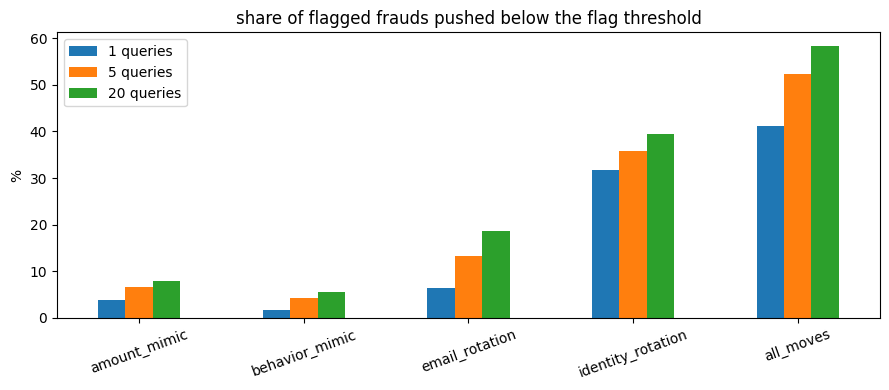

In [3]:
BUDGETS = (1, 5, 20)
res = {}
for name, moves in (("amount_mimic", ["amount_mimic"]), ("behavior_mimic", ["behavior_mimic"]), ("email_rotation", ["email_rotation"]),
                    ("identity_rotation", ["identity_rotation"]), ("all_moves", list(GROUPS))):
    best = evasion.attack(scorer_cal, Xte[targets], COLS, GROUPS, moves, donors, np.random.default_rng(1), BUDGETS)
    res[name] = {q: float((b < thr).mean()) for q, b in best.items()}
df = pd.DataFrame(res).T
df.columns = [f"{q} queries" for q in df.columns]
display((df * 100).round(1).astype(str) + " %")
(df * 100).plot(kind="bar", figsize=(9, 4), title="share of flagged frauds pushed below the flag threshold"); plt.ylabel("%"); plt.xticks(rotation=20)
plt.tight_layout(); plt.show()

## 3. Reading the result

- Moves that only change what an attacker cannot easily fake (amount, hour) barely help them; moves that reset identity-linked history are what evade the model.
- This is a threat model for the *scoring layer* only: real systems add velocity limits, device binding and manual review on top.
- Adversarial training (rotated fraud copies added to the training set) was tested separately and lowered identity-rotation evasion with almost no accuracy loss; the numbers and the caveat that the attack equals the augmentation are in the README.